# Notebook 3: Fleet time-series analysis (`history/last_month/fleet_timeseries.csv`)

In this notebook I use regular snapshots of the fleet to see *when* capacity was busy or free, when queries piled up, and which machine type caused the congestion.

Notebook 2 showed that the fleet was only about 26% utilised *on average*. But an average hides time. A pool can be idle all night and overloaded every afternoon. The scheduler's scaling decisions are about time, so I needed to look at how things changed through the day and the week.

To understand the file, I checked the simulator source. In `engine.py`, `_on_tick` runs every `tick_interval_s` (60 s). It only records a snapshot when `now - last_sample >= 300`, so snapshots are taken **every 300 s (5 minutes)**, not on every tick. At each snapshot, it groups the live instances by `(instance_type, market)` and writes one row per group:

| column | meaning (from the code) |
|---|---|
| `t_s` | the snapshot time, in elapsed simulation seconds (rounded) |
| `instance_type`, `market` | the group |
| `booting`, `warming`, `ready` | the number of machines in each lifecycle state |
| `busy_slots` | the number of queries running on machines in this group |
| `ready_slots` | the total slots on machines in the `ready` state |
| `pending_queries` | `self._n_pending`: the **fleet-wide** number of queries that have arrived but are not running (waiting in the scheduler's queues). The same number is repeated on every row of a snapshot. |

This has two consequences that I need to keep in mind:

1. I have to check the sampling interval from the data instead of assuming it is the 60-second tick.
2. I have to **de-duplicate `pending_queries` by timestamp** before calculating fleet-wide statistics. Otherwise it gets counted three times, once for each machine-type row.

The notebook is organised as follows:

1. Setup and loading
2. Structure, quality and sampling interval
3. Lifecycle states
4. Busy, ready and free slots by machine type
5. Fleet-wide pending queries
6. Daily and weekly shape of the queue
7. Saturation: which machine types were full?
8. Congestion episodes, in detail
9. What was waiting? (link to the query log)
10. Pending queries versus free capacity
11. Summary

## 1. Setup and loading

In this step I import the libraries, find the data, and load the file and the config.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def find_history_dir() -> Path:
    """Return the history/last_month folder, searching upwards from the working directory."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        candidate = base / "history" / "last_month"
        if candidate.is_dir():
            return candidate
    raise FileNotFoundError("Could not find history/last_month. Run from the project folder or analysis/.")


HISTORY_DIR = find_history_dir()
TYPE_ORDER = ["std.small", "std.large", "mem.xlarge"]
TYPE_COLORS = {"std.small": "#2a78d6", "std.large": "#eb6834", "mem.xlarge": "#1baf7a"}
QTYPE_ORDER = ["lookup", "dashboard", "filtered_agg", "adhoc", "report"]
QTYPE_COLORS = {"lookup": "#2a78d6", "dashboard": "#eb6834", "filtered_agg": "#1baf7a",
                "adhoc": "#eda100", "report": "#e87ba4"}
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plt.rcParams.update({
    "figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.edgecolor": "#c3c2b7",
    "axes.titleweight": "bold", "lines.linewidth": 1.5,
})

fleet = pd.read_csv(HISTORY_DIR / "fleet_timeseries.csv")
with open(HISTORY_DIR / "config.json") as f:
    config = json.load(f)
fleet.head(9)

,t_s,instance_type,market,booting,warming,ready,busy_slots,ready_slots,pending_queries
0,60,mem.xlarge,on_demand,6,0,0,0,0,7
1,60,std.large,on_demand,0,6,0,0,0,7
2,60,std.small,on_demand,0,2,0,0,0,7
3,360,mem.xlarge,on_demand,0,6,0,0,0,0
4,360,std.large,on_demand,0,0,6,4,48,0
5,360,std.small,on_demand,0,0,2,0,4,0
6,660,mem.xlarge,on_demand,0,0,6,0,96,0
7,660,std.large,on_demand,0,0,6,3,48,0
8,660,std.small,on_demand,0,0,2,0,4,0


Each snapshot time appears on three rows, one per machine type. At `t = 60`, all machines are still booting or warming (`ready = 0`), and 7 queries are already waiting. At `t = 360`, `std.small` and `std.large` are ready, but `mem.xlarge` is still warming because it needs 570 seconds. `pending_queries` is the same on all three rows of a snapshot, which is the repeated fleet-wide value I described above.

## 2. Structure, quality and sampling interval

Here I check the row and column counts, the types, missing values, duplicates, the number of unique timestamps, the real gap between snapshots, and whether `pending_queries` really is the same across the rows of one timestamp.

If I assumed a 60-second interval, every duration I calculated (for example, how long a queue lasted) would be wrong by a factor of five.

To check the interval, I sort the unique timestamps and take the differences between consecutive ones (`np.diff`). `value_counts()` then shows which gaps occur and how often.

In [2]:
print("Rows, columns:", fleet.shape)
print("\nData types:\n", fleet.dtypes, sep="")
print("\nMissing values:\n", fleet.isna().sum(), sep="")
print("\nDuplicate (t_s, instance_type, market) rows:", fleet.duplicated(["t_s", "instance_type", "market"]).sum())

timestamps = np.sort(fleet["t_s"].unique())
gaps = pd.Series(np.diff(timestamps)).value_counts()
print(f"\nUnique timestamps: {len(timestamps):,}  (first {timestamps[0]}, last {timestamps[-1]:,})")
print("Gaps between consecutive snapshots (seconds -> count):\n", gaps, sep="")
print("Rows per timestamp:", fleet.groupby("t_s").size().value_counts().to_dict())
print("Distinct pending_queries values within one timestamp (max):",
      fleet.groupby("t_s")["pending_queries"].nunique().max())
print("Instance types:", sorted(fleet["instance_type"].unique()), "| markets:", sorted(fleet["market"].unique()))
print(f"Configured tick interval: {config['tick_interval_s']} s")

Rows, columns: (26010, 9)

Data types:
t_s                int64
instance_type        str
market               str
booting            int64
warming            int64
ready              int64
busy_slots         int64
ready_slots        int64
pending_queries    int64
dtype: object

Missing values:
t_s                0
instance_type      0
market             0
booting            0
warming            0
ready              0
busy_slots         0
ready_slots        0
pending_queries    0
dtype: int64

Duplicate (t_s, instance_type, market) rows: 0

Unique timestamps: 8,670  (first 60, last 2,600,760)
Gaps between consecutive snapshots (seconds -> count):
300    8669
Name: count, dtype: int64
Rows per timestamp: {3: 8670}
Distinct pending_queries values within one timestamp (max): 1
Instance types: ['mem.xlarge', 'std.large', 'std.small'] | markets: ['on_demand']
Configured tick interval: 60 s


There are 26,010 rows, which is 8,670 snapshots \* 3 machine types. There are no missing values and no duplicates.

**Every gap is exactly 300 seconds.** Snapshots are taken every 5 minutes, starting at `t = 60` (the first tick), even though the scheduler tick is 60 seconds. This means every duration below is a multiple of 5 minutes.

Within each timestamp, `pending_queries` has exactly one value, which confirms it is a fleet-wide number repeated on each row. From here on I use one value per timestamp.

Only on-demand rows exist, which is consistent with Notebooks 1 and 2.

One limitation is that anything shorter than 5 minutes, such as a 1-minute burst, can fall between snapshots. The query log (Notebook 4) has exact timestamps for that.

### 2.1 Build convenient tables

Here I create a few tables to make the rest of the analysis easier:

- `free_slots = ready_slots - busy_slots` (ready capacity that is not running a query);
- `slot_utilisation = busy_slots / ready_slots` (only where `ready_slots > 0`, to avoid dividing by zero during start-up);
- `queue`: one row per timestamp with the fleet-wide `pending_queries`, plus the day, the hour of the day and the weekday;
- wide tables (one column per machine type) for busy, ready and free slots.

To turn elapsed seconds into days and clock times, I use `day = t_s // 86400` and `hour = (t_s % 86400) / 3600`. The README says `t = 0` is **Monday 00:00 US/Eastern**, so `weekday = WEEKDAYS[day % 7]`. The hours are therefore US/Eastern clock hours. I ignore daylight-saving changes, because the simulator does not model them.

In [3]:
fleet["free_slots"] = fleet["ready_slots"] - fleet["busy_slots"]
fleet["slot_utilisation"] = np.where(fleet["ready_slots"] > 0,
                                     fleet["busy_slots"] / fleet["ready_slots"].where(fleet["ready_slots"] > 0), np.nan)

queue = fleet.groupby("t_s")["pending_queries"].first().rename("pending").to_frame()
queue["day"] = queue.index // 86400
queue["hour"] = (queue.index % 86400) // 3600
queue["hour_float"] = (queue.index % 86400) / 3600
queue["weekday"] = [WEEKDAYS[d % 7] for d in queue["day"]]

busy = fleet.pivot(index="t_s", columns="instance_type", values="busy_slots")[TYPE_ORDER]
ready = fleet.pivot(index="t_s", columns="instance_type", values="ready_slots")[TYPE_ORDER]
free = ready - busy
assert len(queue) == len(timestamps) == len(busy)
assert (free >= 0).all().all(), "busy slots exceed ready slots somewhere"
print("Snapshot tables built:", busy.shape, "| free slots never negative: OK")

Snapshot tables built: (8670, 3) | free slots never negative: OK


There is one wide row per snapshot. Free slots are never negative, which is a good sanity check that `busy_slots` only counts work on ready machines.

## 3. Machine lifecycle states

Here I look at how many machines were booting, warming or ready over time.

A fleet that scales would show machines regularly going through booting and warming. A fixed fleet would only show these states at the very beginning.

In [4]:
state_summary = fleet.groupby("instance_type")[["booting", "warming", "ready"]].agg(["min", "max", "mean"]).loc[TYPE_ORDER]
not_ready = fleet.loc[(fleet["booting"] > 0) | (fleet["warming"] > 0), ["t_s", "instance_type", "booting", "warming", "ready"]]
print("Snapshots where any machine was booting or warming:")
print(not_ready.to_string(index=False))
state_summary

Snapshots where any machine was booting or warming:
 t_s instance_type  booting  warming  ready
  60    mem.xlarge        6        0      0
  60     std.large        0        6      0
  60     std.small        0        2      0
 360    mem.xlarge        0        6      0


booting           warming           ready          
                  min max  mean     min max  mean   min max  mean
instance_type                                                    
std.small           0   0 0.000       0   2 0.000     0   2 2.000
std.large           0   0 0.000       0   6 0.001     0   6 5.999
mem.xlarge          0   6 0.001       0   6 0.001     0   6 5.999

Machines were only booting or warming in the first two snapshots (`t = 60`, and `t = 360` for `mem.xlarge`). After that, every machine was `ready` for the rest of the month: 2, 6 and 6 machines. The `mean` of `ready` is just below the maximum only because of those first few minutes.

So the lifecycle confirms a fixed fleet. There was no scaling.

## 4. Busy, ready and free slots by machine type

For each machine type, I look at the average and maximum number of busy slots, the average number of free slots, and the average slot utilisation over time.

This is the time-based view of utilisation. There is one important difference from Notebook 2: here utilisation is measured from snapshots of **ready time**, not over billed time, and it is sampled every 5 minutes. The two should be similar but not exactly the same.

The statistics I use are:

- **mean**: the sum divided by the number of snapshots (the typical level over time);
- **max**: the highest snapshot;
- **share of snapshots at 100% busy**: the fraction of time a type had no free slot at all.

In [5]:
capacity = pd.DataFrame({
    "slots_when_ready": ready.max(),
    "mean_busy": busy.mean(),
    "max_busy": busy.max(),
    "mean_free": free.mean(),
    "min_free": free.min(),
    "mean_utilisation_pct": (busy.sum() / ready.sum() * 100),
    "share_of_snapshots_full_pct": ((busy >= ready) & (ready > 0)).mean() * 100,
}).loc[TYPE_ORDER]
fleet_busy_share = busy.sum(axis=1).sum() / ready.sum(axis=1).sum()
print(f"Fleet-wide snapshot utilisation (busy slots / ready slots, summed over time): {fleet_busy_share:.1%}")
capacity

Fleet-wide snapshot utilisation (busy slots / ready slots, summed over time): 26.3%


,slots_when_ready,mean_busy,max_busy,mean_free,min_free,mean_utilisation_pct,share_of_snapshots_full_pct
instance_type,,,,,,,
std.small,4,0.039,2,3.961,0,0.975,0.000
std.large,48,7.291,48,40.704,0,15.191,0.173
mem.xlarge,96,31.619,96,64.358,0,32.944,26.505


**`mem.xlarge`** has 96 slots. On average about 32 were busy and 64 were free, but it reached 96 busy (completely full) in **about 26.5% of all snapshots**.

**`std.large`** has 48 slots. On average about 7 were busy and 41 were free, and it was full in only about 0.2% of snapshots.

**`std.small`** has 4 slots. They were almost always free, and the pool was essentially never full.

Fleet-wide snapshot utilisation was about 26%, which agrees with the 26.3% from the instance log. It is a different method that gives the same answer.

This tells me that the queueing problem, if there is one, is a `mem.xlarge` problem. The other two pools had a lot of free capacity nearly all the time. Since the historical scheduler sent each query type to one fixed machine type (Notebook 4), free `std.large` slots could not help the queries waiting for `mem.xlarge`.

### 4.1 Chart: busy slots over the month, per machine type

I used three small panels, one per type, each with its own capacity line. This makes it easy to see how often each pool hit its limit. Using separate panels also avoids comparing a 4-slot pool and a 96-slot pool on the same scale.

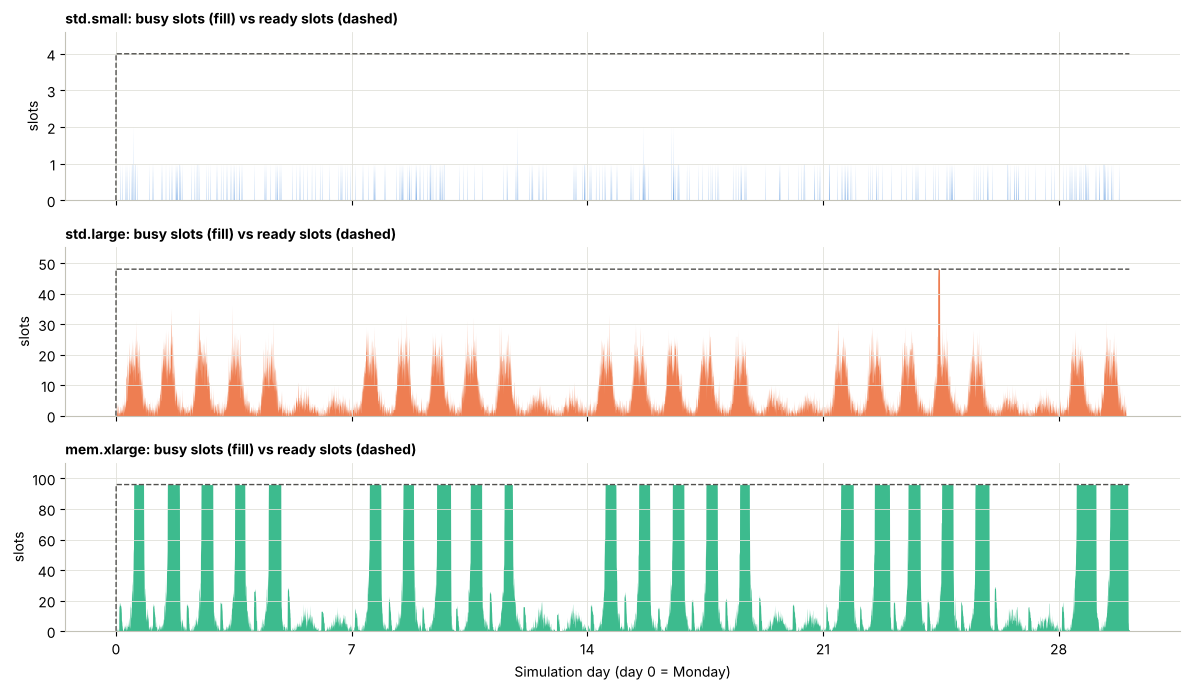

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
days_axis = busy.index / 86400
for ax, t in zip(axes, TYPE_ORDER):
    ax.fill_between(days_axis, busy[t], color=TYPE_COLORS[t], alpha=0.85, linewidth=0)
    ax.plot(days_axis, ready[t], color="#52514e", linewidth=1, linestyle="--")
    ax.set_ylabel("slots")
    ax.set_title(f"{t}: busy slots (fill) vs ready slots (dashed)", loc="left", fontsize=10)
    ax.set_ylim(0, ready[t].max() * 1.15)
axes[-1].set_xlabel("Simulation day (day 0 = Monday)")
axes[-1].set_xticks(range(0, 31, 7))
plt.tight_layout()
plt.show()

Wherever the coloured area touches the dashed line, that pool was full. `mem.xlarge` hits its limit on most weekday afternoons and stays well below it at weekends (days 5 to 6, 12 to 13, 19 to 20 and 26 to 27). `std.large` shows a daily rhythm but rarely gets close to 48. `std.small` barely shows up.

## 5. Fleet-wide pending queries

Here I look at the size of the waiting queue across the whole fleet: its average, median, maximum and distribution.

A query that waits does not earn any extra revenue, and it may miss its SLA. The queue shows when there was not enough capacity *for the way work was routed*.

The statistics I use are:

- **median (50th percentile)**: half of the snapshots have a queue at or below this value;
- **P90, P95, P99**: 90%, 95% and 99% of snapshots are at or below these values, so they describe the bad periods;
- **share of snapshots with an empty queue**.

I use the de-duplicated `queue` table, with one value per timestamp.

In [7]:
pending = queue["pending"]
pending_stats = pending.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99])
print(pending_stats.round(1).to_string())
print(f"\nShare of snapshots with zero pending queries: {(pending == 0).mean():.1%}")
print(f"Share of snapshots with more than 1,000 pending: {(pending > 1000).mean():.1%}")
wrong_mean = fleet["pending_queries"].mean()
wrong_sum = fleet["pending_queries"].sum()
print(f"\nFor illustration only — WRONG ways: row-wise mean {wrong_mean:.1f} (same here because every "
      f"timestamp has 3 rows), row-wise sum {wrong_sum:,} = 3× the de-duplicated sum {pending.sum():,}.")

count   8,670.000
mean      236.200
std       497.500
min         0.000
50%         0.000
75%       118.000
90%       943.000
95%     1,353.000
99%     2,236.200
max     2,989.000

Share of snapshots with zero pending queries: 73.3%
Share of snapshots with more than 1,000 pending: 8.7%

For illustration only — WRONG ways: row-wise mean 236.2 (same here because every timestamp has 3 rows), row-wise sum 6,143,991 = 3× the de-duplicated sum 2,047,997.


The queue was **empty in about 73% of snapshots**, and the median is 0.

However, the distribution is very skewed. The mean is about 236, P90 is about 943, P95 about 1,353, P99 about 2,236, and at the maximum **2,989** queries were waiting. About 1 snapshot in 10 had more than 1,000 queries waiting.

A **skewed** distribution like this, mostly zero but sometimes very large, is why the mean on its own is misleading. No "typical" snapshot had 236 queries waiting. Most had none, and some had thousands.

The last line shows why de-duplication matters: adding up the raw column counts every queue three times. (The row-wise mean happens to be the same here only because each timestamp always has exactly three rows. That would stop being true as soon as the number of groups changed, for example once spot machines appear.)

### 5.1 Chart: pending queries over the month

A single time series shows the rhythm of the congestion across days and weeks.

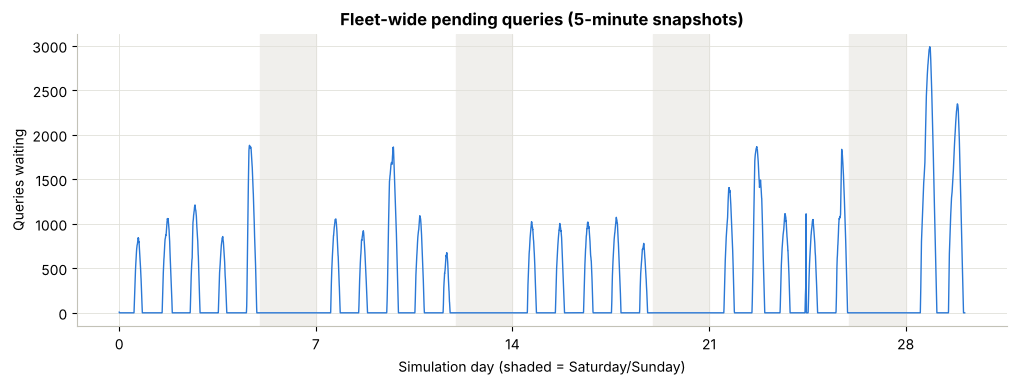

In [8]:
fig, ax = plt.subplots(figsize=(12, 3.8))
for d in range(30):
    if d % 7 in (5, 6):
        ax.axvspan(d, d + 1, color="#f0efec", zorder=0)
ax.plot(queue.index / 86400, pending, color="#2a78d6", linewidth=1)
ax.set_xlabel("Simulation day (shaded = Saturday/Sunday)")
ax.set_ylabel("Queries waiting")
ax.set_title("Fleet-wide pending queries (5-minute snapshots)")
ax.set_xticks(range(0, 31, 7))
plt.show()

A queue builds up almost every weekday afternoon and drains overnight. Weekends (shaded) have essentially no queue. The largest peaks happen late in the month.

## 6. Daily and weekly shape of the queue

Here I look at the average queue by hour of the day and by weekday.

If congestion comes back at predictable times, a scheduler can add capacity *before* the queue forms instead of reacting after it has formed. This is important because a `mem.xlarge` needs 9.5 minutes to become ready.

I group the de-duplicated queue by `hour` (0 to 23) and by `weekday`, and calculate the mean and the 90th percentile. The P90 shows how bad the worse days were in each hour.

In [9]:
by_hour = queue.groupby("hour")["pending"].agg(mean="mean", p90=lambda s: s.quantile(0.9), max="max")
by_weekday = queue.groupby("weekday")["pending"].agg(mean="mean", p90=lambda s: s.quantile(0.9),
                                                       max="max").reindex(WEEKDAYS)
print("Average pending queries by weekday:")
print(by_weekday.round(0).to_string())
by_hour.round(0).T

Average pending queries by weekday:
           mean       p90   max
weekday                        
Mon     377.000 1,170.000  2989
Tue     403.000 1,435.000  2348
Wed     305.000 1,071.000  1863
Thu     215.000   856.000  1112
Fri     274.000 1,073.000  1882
Sat       0.000     0.000     0
Sun       0.000     0.000     0


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
mean,57.000,23.000,4.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,14.000,2.000,19.000,321.000,598.000,765.000,846.000,852.000,740.000,567.000,383.000,242.000,155.000,99.000
p90,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,82.000,624.000,"1,154.000","1,512.000","1,677.000","1,791.000","1,700.000","1,445.000","1,268.000",808.000,273.000,0.000
max,"1,529.000",938.000,351.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,"1,112.000",772.000,291.000,"1,082.000","1,843.000","1,882.000","2,000.000","2,514.000","2,774.000","2,949.000","2,989.000","2,973.000","2,628.000","2,098.000"


**By hour of the day (US/Eastern):** the queue is close to zero from about 02:00 to 12:00. It starts rising at 13:00, peaks between roughly 15:00 and 18:00 (about 750 to 850 waiting on average, with P90 well above 1,000), and drains through the evening, usually by 02:00 to 03:00.

**By weekday:** Monday to Friday average roughly 200 to 400 waiting, while **Saturday and Sunday average 0**.

My interpretation is that congestion follows a strong pattern and builds up on weekday afternoons. It starts *after* the noon peak in arrivals (Notebook 4 shows that the `adhoc` and `report` load arrives around 12:00 to 17:00), which fits with long queries piling up on a fixed pool.

What I cannot conclude is that this pattern will hold. The hourly averages only describe this month, and the README warns that traffic can change without notice in the hidden scenarios. So the scheduler should react to the live queue. A time-of-day pattern can help, but the scheduler should not depend on it.

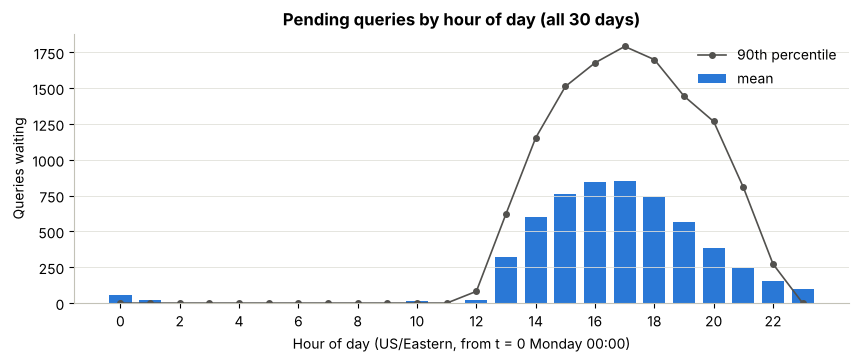

In [10]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(by_hour.index, by_hour["mean"], color="#2a78d6", width=0.75, label="mean")
ax.plot(by_hour.index, by_hour["p90"], color="#52514e", marker="o", markersize=4, linewidth=1.2, label="90th percentile")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day (US/Eastern, from t = 0 Monday 00:00)")
ax.set_ylabel("Queries waiting")
ax.set_title("Pending queries by hour of day (all 30 days)")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)
plt.show()

The bars are the average queue for each clock hour across all days. Weekends are included, which pulls the averages down. The line is the 90th percentile, which describes a bad weekday. The afternoon hump is the congestion window that comes back every weekday.

## 7. Saturation: which machine types were full?

Here I check whether the whole fleet or only some machine types were congested when the queue was large.

If all the pools were full, the fleet was simply too small. If only one pool was full while the others were idle, the problem was routing and pool sizing, which a scheduler can fix by moving work or resizing the right pool.

I call a type **saturated** in a snapshot when `busy_slots == ready_slots`, meaning there is no free slot. I compare saturation in snapshots with a large queue (more than 1,000) against all snapshots, and I count how often each combination of saturated types happens.

In [11]:
saturated = (busy >= ready) & (ready > 0)
big_queue = queue["pending"] > 1000
sat_compare = pd.DataFrame({
    "all snapshots (% saturated)": saturated.mean() * 100,
    "snapshots with >1,000 pending (% saturated)": saturated.loc[big_queue].mean() * 100,
    "snapshots with 0 pending (% saturated)": saturated.loc[queue["pending"] == 0].mean() * 100,
}).loc[TYPE_ORDER]

combo = saturated.apply(lambda row: "+".join(t for t in TYPE_ORDER if row[t]) or "none", axis=1)
combo_table = pd.crosstab(combo, pd.cut(queue["pending"], [-1, 0, 100, 1000, np.inf],
                                        labels=["0", "1-100", "101-1000", ">1000"]))
print("Saturated machine-type combinations (rows) by queue size (columns), number of snapshots:")
print(combo_table.to_string())
sat_compare.round(2)

Saturated machine-type combinations (rows) by queue size (columns), number of snapshots:
pending        0  1-100  101-1000  >1000
row_0                                   
mem.xlarge     1    121      1422    754
none        6356      1         0      0
std.large      1      3         9      2


,all snapshots (% saturated),"snapshots with >1,000 pending (% saturated)",snapshots with 0 pending (% saturated)
instance_type,,,
std.small,0.000,0.000,0.000
std.large,0.170,0.260,0.020
mem.xlarge,26.510,99.740,0.020


When more than 1,000 queries were waiting, **`mem.xlarge` was saturated in 99.7% of snapshots**. At the same time, `std.small` was never saturated and `std.large` only rarely.

In snapshots with an empty queue, almost nothing was saturated. This is what I expected, because a full pool with work left over leaves queries waiting.

The cross-tabulation shows that `mem.xlarge` was the only saturated pool in about 2,300 snapshots. `std.large` was saturated on its own in only 15 snapshots, but two of those had more than 1,000 queries waiting. That small group is a different event, which I look at in Section 8.2.

There was no snapshot where two or three pools were saturated at the same time, so the whole fleet was never full at once.

This means congestion was **not fleet-wide**. Almost always it was the `mem.xlarge` pool, while the other pools had dozens of idle slots at the same moment. It is a routing and sizing problem, not a "too few machines overall" problem.

## 8. Congestion episodes in detail

Here I look at each continuous period of queue build-up: when it started, how long it lasted, and how high it peaked.

Turning a noisy time series into a list of episodes gives me a few events that I can explain. The duration matters because SLAs are time limits.

I define an episode as a run of consecutive snapshots with `pending > 0`. I label the runs by finding where the condition changes (`(cond != cond.shift()).cumsum()`) and then group them. The duration is the number of snapshots \* 300 s, which is only accurate to within plus or minus 5 minutes because of the sampling interval.

In [12]:
in_queue = queue["pending"] > 0
run_id = (in_queue != in_queue.shift()).cumsum()
episodes = (queue.loc[in_queue].assign(run=run_id[in_queue])
            .groupby("run").agg(start_s=("pending", lambda s: s.index.min()),
                                end_s=("pending", lambda s: s.index.max()),
                                snapshots=("pending", "size"), peak=("pending", "max"),
                                mean_pending=("pending", "mean")))
episodes["duration_h"] = episodes["snapshots"] * 300 / 3600
episodes["start_day"] = episodes["start_s"] // 86400
episodes["start_weekday"] = [WEEKDAYS[d % 7] for d in episodes["start_day"]]
episodes["start_clock"] = [f"{int((s % 86400) // 3600):02d}:{int((s % 3600) // 60):02d}" for s in episodes["start_s"]]
episodes["peak_at_s"] = [queue.loc[r.start_s:r.end_s, "pending"].idxmax() for r in episodes.itertuples()]
episodes["peak_clock"] = [f"day {int(p // 86400)} {int((p % 86400) // 3600):02d}:{int((p % 3600) // 60):02d}"
                          for p in episodes["peak_at_s"]]
major = episodes.loc[episodes["peak"] > 100]
print(f"Episodes with any queue: {len(episodes)}; with peak > 100: {len(major)}")
print(f"Median duration of episodes with peak > 100: {major['duration_h'].median():.1f} h")
major.sort_values("peak", ascending=False).head(12)[
    ["start_day", "start_weekday", "start_clock", "duration_h", "peak", "peak_clock", "mean_pending"]]

Episodes with any queue: 24; with peak > 100: 23
Median duration of episodes with peak > 100: 8.2 h


,start_day,start_weekday,start_clock,duration_h,peak,peak_clock,mean_pending
run,,,,,,,
45,28,Mon,12:36,14.083,2989,day 28 20:41,"1,781.722"
47,29,Tue,12:36,12.750,2348,day 29 20:11,"1,452.314"
11,4,Fri,12:46,8.833,1882,day 4 15:21,"1,189.547"
35,22,Tue,12:41,10.750,1867,day 22 16:46,"1,227.829"
17,9,Wed,12:36,10.000,1863,day 9 18:16,"1,166.950"
43,25,Fri,12:26,10.000,1837,day 25 17:21,999.325
33,21,Mon,12:41,9.000,1406,day 21 17:01,864.907
7,2,Wed,12:41,8.417,1212,day 2 16:46,761.198
37,23,Wed,12:41,8.583,1112,day 23 16:46,709.981


There are only 24 episodes, and 23 of them peak above 100. So the queues were not random noise: they came as large events that lasted for hours.

Almost every major episode starts on a **weekday at about 12:30**, lasts **8 to 14 hours** (the median is about 8 hours) and peaks in the late afternoon or evening. The largest peaks (about 2,350 to 3,000 waiting) are on days 28 and 29, the Monday and Tuesday of the final, partial week.

**One episode is different.** On day 24 (a Thursday), it starts at **10:01**, lasts only about 1.2 hours and peaks at 1,112. It does not fit the afternoon pattern, so I look at it separately in Section 8.2.

My interpretation is that on weekdays the `mem.xlarge` pool takes in a midday wave of long-running work, falls behind, and catches up overnight. That is what a pool that is too small for its afternoon demand looks like, rather than random spikes.

### 8.1 The largest queues: what did each machine type look like?

Here I look at the busy and free slots of every machine type at the snapshots with the largest queues.

The task asks to compare all machine types at the worst moments, and I wanted to confirm that only one pool was the bottleneck.

In [13]:
top_times = queue["pending"].nlargest(5).index
worst = pd.concat({
    "busy": busy.loc[top_times], "free": free.loc[top_times]}, axis=1)
worst.insert(0, "pending", queue.loc[top_times, "pending"])
worst.insert(1, "when", [f"day {t // 86400} ({WEEKDAYS[(t // 86400) % 7]}) "
                         f"{(t % 86400) // 3600:02d}:{(t % 3600) // 60:02d}" for t in top_times])
worst

pending                when      busy                           free                     
instance_type                             std.small std.large mem.xlarge std.small std.large mem.xlarge
t_s                                                                                                    
2493660          2989  day 28 (Mon) 20:41         0         4         96         4        44          0
2493060          2987  day 28 (Mon) 20:31         0         5         96         4        43          0
2493360          2986  day 28 (Mon) 20:36         1         4         96         3        44          0
2493960          2986  day 28 (Mon) 20:46         0         2         96         4        46          0
2494260          2982  day 28 (Mon) 20:51         0         5         96         4        43          0

At each of the five worst snapshots (all on day 28, a Monday, around 20:30), `mem.xlarge` had **96 busy and 0 free** slots. Meanwhile, `std.large` had about 43 to 46 of its 48 slots free, and `std.small` had all 4 free. Roughly 3,000 queries were waiting for one pool while about 50 slots in other pools were idle.

### 8.2 The day-24 morning episode: a `std.large` congestion event

Here I look at the one major episode that started at 10:01 instead of midday, and at the snapshots where `std.large` (not `mem.xlarge`) was full.

A scheduler has to handle sudden traffic changes that nobody announces (the README says traffic can change with no notice). This episode is the only example in the history of a short-SLA pool becoming the bottleneck.

I look at the busy and free slots in the snapshots of day 24 between 09:30 and 11:30. Then, in the next section, after loading the query log, I check what was waiting.

In [14]:
day24 = (queue.index >= 24 * 86400 + 9.5 * 3600) & (queue.index <= 24 * 86400 + 11.5 * 3600)
episode24 = pd.concat({"busy": busy.loc[day24], "free": free.loc[day24]}, axis=1)
episode24.insert(0, "pending", queue.loc[day24, "pending"])
episode24.insert(0, "clock", [f"{(t % 86400) // 3600:02d}:{(t % 3600) // 60:02d}" for t in episode24.index])
episode24

clock pending      busy                           free                     
instance_type                std.small std.large mem.xlarge std.small std.large mem.xlarge
t_s                                                                                       
2107860        09:31       0         0        10          7         4        38         89
2108160        09:36       0         0        17          3         4        31         93
2108460        09:41       0         0        17          5         4        31         91
2108760        09:46       0         0        17          6         4        31         90
2109060        09:51       0         1        48          4         3         0         92
2109360        09:56       0         0        45          5         4         3         91
2109660        10:01      16         0        48          7         4         0         89
2109960        10:06      79         0        48          6         4         0         90
2110260        10:11     129         0        48         10         4         0         86
2110560        10:16     149         0        48         15         4         0         81
2110860        10:21     200         0        48         12         4         0         84
2111160        10:26     226         0        48         14         4         0         82
2111460        10:31     273         0        48         14         4         0         82
2111760        10:36     287         0        48         15         4         0         81
2112060        10:41     565         0        48         11         4         0         85
2112360        10:46     886         0        48          8         4         0         88
2112660        10:51    1002         0        48          9         4         0         87
2112960        10:56    1112         0        48         10         4         0         86
2113260        11:01     772         0        48         17         4         0         79
2113560        11:06      17         0        48         27         4         0         69
2113860        11:11       0         0        33         26         4        15         70
2114160        11:16       0         0        17         20         4        31         76
2114460        11:21       0         0        19         31         4        29         65
2114760        11:26       0         0        27         27         4        21         69

From about 10:00, the `std.large` pool goes from partly busy to **48 of 48 slots busy**, and the queue climbs to over 1,000 within an hour. During the same time, `mem.xlarge` has plenty of free slots. By about 11:10 the pool catches up and the queue disappears.

This is the opposite of the afternoon pattern: here the expensive pool was idle and the mid-size pool was overloaded. Section 9 shows what was waiting, and Notebook 4 shows the cause (a surge of `filtered_agg` arrivals) and the result (almost all of the month's `dashboard` SLA misses).

## 9. What was waiting? Linking the queue to the query log

Here I find out which clients and query types made up the queue.

The fleet time series only counts the waiting queries; it does not say what they are. This matters for the scheduler, because a waiting `adhoc` query (30-minute SLA for `labs_ds`) is a very different problem from a waiting `dashboard` query (10-second SLA).

In the query log, a query is *waiting* at time `t` if `arrival_s <= t < start_s`. Every historical query was started (Notebook 4 shows that all of them completed, in one attempt each), so:

`waiting(t) = count(arrival_s <= t) - count(start_s <= t)`

I use `np.searchsorted` on the sorted arrival and start times to calculate these counts for all 8,670 snapshots at once. I first check that this reconstruction reproduces the `pending_queries` column exactly, and only then break it down by query type and client.

In [15]:
qlog = pd.read_csv(HISTORY_DIR / "query_log.csv.gz",
                   usecols=["client_id", "query_type", "arrival_s", "start_s", "instance_type", "status", "attempts"])
assert (qlog["status"] == "completed").all() and (qlog["attempts"] == 1).all(), \
    "reconstruction assumes every query started exactly once"
snap_t = queue.index.to_numpy(dtype=float)


def waiting_counts(frame: pd.DataFrame) -> np.ndarray:
    arrivals = np.sort(frame["arrival_s"].to_numpy())
    starts = np.sort(frame["start_s"].to_numpy())
    return np.searchsorted(arrivals, snap_t, side="right") - np.searchsorted(starts, snap_t, side="right")


queue["reconstructed"] = waiting_counts(qlog)
mismatch = (queue["reconstructed"] != queue["pending"]).sum()
print(f"Snapshots where reconstruction != pending_queries: {mismatch} of {len(queue):,}")
print(f"Max absolute difference: {(queue['reconstructed'] - queue['pending']).abs().max()}")

Snapshots where reconstruction != pending_queries: 1 of 8,670
Max absolute difference: 1


The reconstruction from the query log matches the fleet file's `pending_queries` at 8,669 of the 8,670 snapshots. The one exception is off by a single query. This is what I would expect when an arrival or start happens exactly at a snapshot time and the engine orders its events differently from my `<=` convention. The two files tell the same story, so I can safely break the queue down using fields from the query log.

In [16]:
waiting_by_type = pd.DataFrame({qt: waiting_counts(g) for qt, g in qlog.groupby("query_type")},
                               index=queue.index)[QTYPE_ORDER]
waiting_by_client_type = pd.DataFrame({f"{c} / {qt}": waiting_counts(g)
                                       for (c, qt), g in qlog.groupby(["client_id", "query_type"])},
                                      index=queue.index)
share_in_big = (waiting_by_client_type.loc[big_queue].sum() / waiting_by_client_type.loc[big_queue].sum().sum() * 100)
share_all = waiting_by_client_type.sum() / waiting_by_client_type.sum().sum() * 100
composition = pd.DataFrame({"share of all waiting query-snapshots (%)": share_all,
                            "share when >1,000 pending (%)": share_in_big}).sort_values(
                                "share of all waiting query-snapshots (%)", ascending=False)
t24 = queue.loc[day24, "pending"].idxmax()
print(f"Queue composition at the day-24 peak (t = {t24}):")
print(waiting_by_client_type.loc[t24].loc[lambda s: s > 0].sort_values(ascending=False).to_string())
print()
print("Queue composition at the single worst snapshot:")
print(waiting_by_client_type.loc[top_times[0]].loc[lambda s: s > 0].sort_values(ascending=False).to_string())
composition.round(2)

Queue composition at the day-24 peak (t = 2112960):
acme_retail / dashboard       1049
acme_retail / filtered_agg      37
trial_pool / dashboard          15
finpay / filtered_agg           11

Queue composition at the single worst snapshot:
labs_ds / adhoc       2619
trial_pool / adhoc     370


,share of all waiting query-snapshots (%),"share when >1,000 pending (%)"
labs_ds / adhoc,79.380,82.560
trial_pool / adhoc,15.540,14.540
labs_ds / report,4.800,2.720
acme_retail / dashboard,0.230,0.170
acme_retail / filtered_agg,0.040,0.010
trial_pool / dashboard,0.000,0.000
finpay / filtered_agg,0.000,0.000
acme_retail / report,0.000,0.000
finpay / lookup,0.000,0.000


At the **day-24 peak**, the queue was mostly `acme_retail / dashboard` (about 1,050 queries), with a few dozen `filtered_agg` queries from `acme_retail` and `finpay` and a handful of `trial_pool` dashboards. Dashboards (benchmark 3 s, SLA 10 s) were stuck behind 240-second `filtered_agg` jobs that had filled the `std.large` slots.

At the worst snapshot, the queue was entirely **`labs_ds / adhoc`** (by far the largest part) and **`trial_pool / adhoc`**. These are exactly the queries the historical scheduler sent to `mem.xlarge` (Notebook 4).

Over all snapshots, `adhoc` makes up the vast majority of waiting query-time, followed at a distance by `report`. `lookup`, `dashboard` and `filtered_agg` add almost nothing, because their pools had spare capacity.

The unit "query-snapshots" means that each waiting query is counted once for every snapshot it was waiting in, so long waits count more. It measures how much waiting built up, not the number of different queries.

My interpretation is that `labs_ds` paid the price of the congestion (Notebook 4 shows that about 79% of its `adhoc` queries missed their 30-minute SLA). `trial_pool` also waited. That costs nothing in penalties, since its penalty is \$0, but it competes with paying work for the same slots.

### 9.1 Chart: queue composition by query type, a typical congested week

A stacked area chart over one week (days 21 to 27) shows how the queue is made up of different query types over time. I picked one week to keep the chart readable; the pattern is the same in the other weeks.

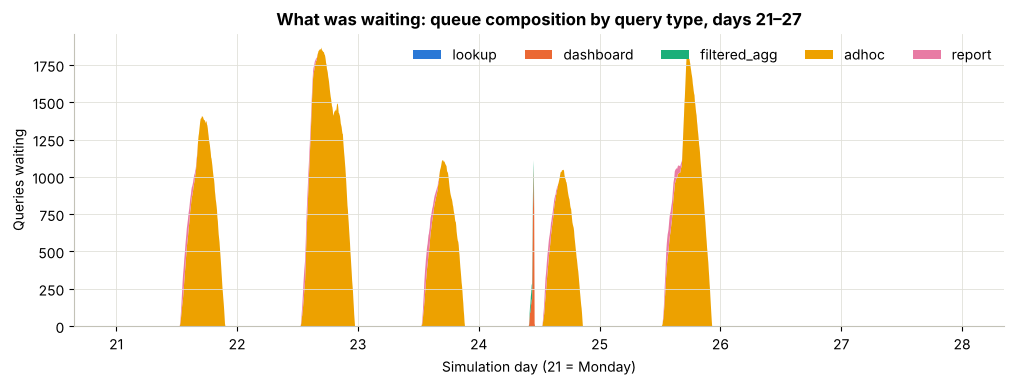

In [17]:
week = waiting_by_type.loc[(waiting_by_type.index >= 21 * 86400) & (waiting_by_type.index < 28 * 86400)]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.stackplot(week.index / 86400, [week[q] for q in QTYPE_ORDER],
             colors=[QTYPE_COLORS[q] for q in QTYPE_ORDER], labels=QTYPE_ORDER, linewidth=0)
ax.set_xlabel("Simulation day (21 = Monday)")
ax.set_ylabel("Queries waiting")
ax.set_title("What was waiting: queue composition by query type, days 21–27")
ax.legend(frameon=False, loc="upper right", ncol=5)
plt.show()

The height of each coloured band is the number of waiting queries of that type. The `adhoc` band dominates every weekday afternoon wave, and `report` adds a thinner layer on top. The weekend (days 26 and 27) is flat.

## 10. Pending queries versus available capacity

Here I look at how the queue relates to free capacity, both fleet-wide and for the `mem.xlarge` pool.

If the queue only grows when the relevant pool has no free slots, then free slots in *that pool* are the right signal for scaling, and fleet-wide free slots would be a misleading signal.

I group snapshots by the number of free `mem.xlarge` slots and calculate the median number of waiting `adhoc + report` queries in each group. I also calculate the Spearman rank correlation between free slots and queue length. *Spearman correlation* measures whether two quantities tend to move in the same order (when one goes up, the other goes up or down), without assuming a straight-line relationship. It ranges from -1 to +1. A correlation shows that two things move together, not that one causes the other.

In [18]:
mem_queue = waiting_by_type[["adhoc", "report"]].sum(axis=1)
other_queue = waiting_by_type[["lookup", "dashboard", "filtered_agg"]].sum(axis=1)
bins = pd.cut(free["mem.xlarge"], [-1, 0, 4, 16, 48, 96], labels=["0", "1-4", "5-16", "17-48", "49-96"])
by_free = pd.DataFrame({"snapshots": bins.value_counts().sort_index(),
                        "median waiting adhoc+report": mem_queue.groupby(bins, observed=False).median(),
                        "mean waiting adhoc+report": mem_queue.groupby(bins, observed=False).mean()})
fleet_free_total = free.sum(axis=1)
print("Spearman correlation, free mem.xlarge slots vs waiting adhoc+report:",
      round(free["mem.xlarge"].corr(mem_queue, method="spearman"), 3))
print("Spearman correlation, fleet-wide free slots vs total pending:",
      round(fleet_free_total.corr(queue["pending"], method="spearman"), 3))
print("Max queries waiting for std.* pools (lookup/dashboard/filtered_agg) at any snapshot:", other_queue.max())
by_free.round(1)

Spearman correlation, free mem.xlarge slots vs waiting adhoc+report: -0.76
Spearman correlation, fleet-wide free slots vs total pending: -0.754
Max queries waiting for std.* pools (lookup/dashboard/filtered_agg) at any snapshot: 1112


,snapshots,median waiting adhoc+report,mean waiting adhoc+report
mem.xlarge,,,
0,2300,807.000,887.900
1-4,8,0.000,0.000
5-16,12,0.000,0.000
17-48,106,0.000,0.000
49-96,6244,0.000,0.000


When `mem.xlarge` had **0 free slots**, a typical snapshot had hundreds of `adhoc`/`report` queries waiting. With **any** free `mem.xlarge` slots, the median number waiting was 0.

The rank correlation between free `mem.xlarge` slots and its queue is strongly negative: more free slots go with fewer waiting queries. That is the pattern I would expect for a queue served by one pool. It is consistent with a causal link, but it does not prove one.

The fleet-wide correlation is almost the same (about -0.75). That does not mean fleet-wide free capacity is a good signal. `mem.xlarge` provides 96 of the 148 slots, so it drives most of the movement in the fleet total. The table above is better evidence: whenever `mem.xlarge` had even one free slot, its queue was essentially empty, no matter how many `std.large` slots were free.

Queries sent to the `std.*` pools only waited during the day-24 event (up to 1,112 at once). The rest of the time, their queues were close to zero.

For the scheduler, this means scaling signals have to be **per pool** (queue length and free slots per machine type, or even better, per query class), not fleet-wide totals.

## 11. Summary of findings

**What I observed**

- Snapshots were taken every **300 seconds** (not every 60-second tick): 8,670 timestamps \* 3 machine types, on-demand only.
- Machines were only booting or warming in the first 10 minutes or so. After that, 2, 6 and 6 machines were ready the whole time.
- `mem.xlarge` was **completely full in about 26.5% of snapshots**, `std.large` in about 0.2%, and `std.small` in about 0%.
- The fleet-wide queue (de-duplicated) was empty about 73% of the time but reached **2,989**, with P95 at about 1,353.
- Congestion came back on **weekday afternoons and evenings** (from about 13:00 to about 02:00 US/Eastern) and did not happen at weekends.
- At the worst moments, `mem.xlarge` was full while about 45 `std.large` slots and 4 `std.small` slots were idle.
- There was one different event: on **day 24, from around 10:00 to 11:10**, a surge of `filtered_agg` arrivals filled the `std.large` pool, and over a thousand `dashboard` queries waited behind 240-second jobs.
- The queue was almost entirely **`labs_ds/adhoc`**, plus `trial_pool/adhoc` and some `report`. The reconstruction from the query log matched `pending_queries` at 8,669 of the 8,670 snapshots.

**How I interpret this**

- The bottleneck was one pool (`mem.xlarge`). It was caused by sending all `adhoc` and `report` work to it and keeping its size fixed.
- The fleet was too big (at night, at weekends and in the `std.*` pools) and too small (`mem.xlarge` on weekday afternoons) at the same time.

**Limitations**

- Sampling every 5 minutes misses very short bursts.
- The data reflect one routing policy, so I cannot see what would have happened with different routing.

**What this means for the scheduler**

- Scale the long-query pool up during the weekday afternoon wave, and down at night and at weekends.
- Use queue signals per pool or per query class.
- Allow overflow: when the preferred pool is full, a long query may be better off on another type (for example, `adhoc` on `std.large`, with a 1,125 s benchmark against a 1,800 s SLA) than waiting hours for `mem.xlarge`.
- Give paying work priority over `trial_pool` when capacity is short.